In [1]:
import torch
import transformers
import sklearn
import pandas as pd
import numpy as np

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)

PyTorch: 2.5.1
Transformers: 4.57.1
Scikit-learn: 1.7.2


In [6]:
import os

DATA_DIR = os.path.join(os.path.expanduser("~"), "Downloads", "TwiBot-20")

files = ["train.json", "dev.json", "test.json", "support.json"]

for f in files:
    path = os.path.join(DATA_DIR, f)
    print(f"{f}: {os.path.exists(path)}")

train.json: True
dev.json: True
test.json: True
support.json: True


In [1]:
import os
import pandas as pd

DATA_DIR = os.path.join(os.path.expanduser("~"), "Downloads", "TwiBot-20")
# If the JSON files are directly in Downloads (no TwiBot-20 subfolder):
# DATA_DIR = os.path.join(os.path.expanduser("~"), "Downloads")

train_df = pd.read_json(os.path.join(DATA_DIR, "train.json"), dtype=False)
dev_df   = pd.read_json(os.path.join(DATA_DIR, "dev.json"),   dtype=False)
test_df  = pd.read_json(os.path.join(DATA_DIR, "test.json"),  dtype=False)


print("Train  :", train_df.shape)
print("Dev    :", dev_df.shape)
print("Test   :", test_df.shape)


Train  : (8278, 6)
Dev    : (2365, 6)
Test   : (1183, 6)


In [2]:
print(train_df.columns.tolist())

['ID', 'profile', 'tweet', 'neighbor', 'domain', 'label']


In [3]:
sample = train_df.iloc[0]

print("ID:")
print(sample["ID"])

print("\nPROFILE:")
print(sample["profile"])

print("\nTWEETS:")
print(sample["tweet"][:3])

print("\nNEIGHBORS:")
print(sample["neighbor"])

print("\nDOMAIN:")
print(sample["domain"])

print("\nLABEL:")
print(sample["label"])

ID:
17461978

PROFILE:
{'id': '17461978 ', 'id_str': '17461978 ', 'name': 'SHAQ ', 'screen_name': 'SHAQ ', 'location': 'Orlando, FL ', 'profile_location': "{'id': '55b4f9e5c516e0b6', 'url': 'https://api.twitter.com/1.1/geo/id/55b4f9e5c516e0b6.json', 'place_type': 'unknown', 'name': 'Orlando, FL', 'full_name': 'Orlando, FL', 'country_code': '', 'country': '', 'contained_within': [], 'bounding_box': None, 'attributes': {}} ", 'description': 'VERY QUOTATIOUS, I PERFORM RANDOM ACTS OF SHAQNESS ', 'url': 'https://t.co/7hsiK8cCKW ', 'entities': "{'url': {'urls': [{'url': 'https://t.co/7hsiK8cCKW', 'expanded_url': 'http://www.ShaqFuRadio.com', 'display_url': 'ShaqFuRadio.com', 'indices': [0, 23]}]}, 'description': {'urls': []}} ", 'protected': 'False ', 'followers_count': '15349596 ', 'friends_count': '692 ', 'listed_count': '45568 ', 'created_at': 'Tue Nov 18 10:27:25 +0000 2008 ', 'favourites_count': '142 ', 'utc_offset': 'None ', 'time_zone': 'None ', 'geo_enabled': 'True ', 'verified': 'T

In [4]:
import re
import numpy as np
import pandas as pd

def clean_text(text):

    if text is None:
        return ""

    if isinstance(text, float) and np.isnan(text):
        return ""

    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove mentions
    text = re.sub(r"@\w+", " ", text)

    # Remove excessive whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [5]:
def get_description(profile):

    if not isinstance(profile, dict):
        return ""

    description = profile.get("description", "")

    if description is None:
        return ""

    return clean_text(description)

In [6]:
train_df["description"] = train_df["profile"].apply(get_description)

print(train_df["description"].head())

0    VERY QUOTATIOUS, I PERFORM RANDOM ACTS OF SHAQ...
1                                                     
2    Owner @ Parscale Strategy. Senior Advisor Digi...
3    Bringing you the important stuff like breaking...
4    MOTIVATION 3 OUT NOW 🔥 Singles: ‘Lil Shawdy’ &...
Name: description, dtype: object


In [7]:
def extract_tweets(tweet_data):

    if tweet_data is None:
        return []

    if isinstance(tweet_data, float) and np.isnan(tweet_data):
        return []

    if not isinstance(tweet_data, list):
        return []

    return [
        clean_text(x)
        for x in tweet_data
        if clean_text(x) != ""
    ]

In [8]:
train_df["tweets_clean"] = train_df["tweet"].apply(extract_tweets)

In [9]:
def combine_text(row):

    profile_text = row["description"]

    tweets = row["tweets_clean"]

    tweet_text = " ".join(tweets)

    return (profile_text + " " + tweet_text).strip()

train_df["text"] = train_df.apply(combine_text, axis=1)

In [10]:
before = len(train_df)

train_df = train_df.drop_duplicates(subset=["ID"])

after = len(train_df)

print("Records before duplicate removal:", before)
print("Records after duplicate removal :", after)
print("Duplicates removed:", before - after)

Records before duplicate removal: 8278
Records after duplicate removal : 8278
Duplicates removed: 0


In [11]:
profile_keys = set()

for profile in train_df["profile"]:
    if isinstance(profile, dict):
        profile_keys.update(profile.keys())

print(sorted(profile_keys))

['contributors_enabled', 'created_at', 'default_profile', 'default_profile_image', 'description', 'entities', 'favourites_count', 'followers_count', 'friends_count', 'geo_enabled', 'has_extended_profile', 'id', 'id_str', 'is_translation_enabled', 'is_translator', 'lang', 'listed_count', 'location', 'name', 'profile_background_color', 'profile_background_image_url', 'profile_background_image_url_https', 'profile_background_tile', 'profile_image_url', 'profile_image_url_https', 'profile_link_color', 'profile_location', 'profile_sidebar_border_color', 'profile_sidebar_fill_color', 'profile_text_color', 'profile_use_background_image', 'protected', 'screen_name', 'statuses_count', 'time_zone', 'url', 'utc_offset', 'verified']


In [12]:
def safe_number(x):

    try:
        return float(x)
    except:
        return 0.0

In [13]:
def behavioural_features(profile, tweets):

    if not isinstance(profile, dict):
        profile = {}

    followers = safe_number(
        profile.get("followers_count", 0)
    )

    following = safe_number(
        profile.get("friends_count", 0)
    )

    statuses = safe_number(
        profile.get("statuses_count", 0)
    )

    favourites = safe_number(
        profile.get("favourites_count", 0)
    )

    followers_following_ratio = (
        followers / (following + 1)
    )

    tweet_count = len(tweets)

    return [
        followers,
        following,
        statuses,
        favourites,
        followers_following_ratio,
        tweet_count
    ]

In [14]:
behaviour_matrix = []

for _, row in train_df.iterrows():

    features = behavioural_features(
        row["profile"],
        row["tweets_clean"]
    )

    behaviour_matrix.append(features)

behaviour_matrix = np.array(behaviour_matrix)

print("Behavioural feature matrix:")
print(behaviour_matrix.shape)

Behavioural feature matrix:
(8278, 6)


In [16]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

text_model = AutoModel.from_pretrained(MODEL_NAME)

print("Tokenizer loaded")
print("Transformer loaded")

Tokenizer loaded
Transformer loaded


In [17]:
MAX_LENGTH = 128

def prepare_text(text):
    return text[:5000]

In [18]:
train_df["model_text"] = train_df["text"].apply(prepare_text)

print(train_df["model_text"].iloc[0][:500])

VERY QUOTATIOUS, I PERFORM RANDOM ACTS OF SHAQNESS RT : 🎉 Are you ready to see what our newest ship’s name will be? 🎉 Thanks to all our partners for helping us unbox the name.… Who has time for receipts? Not me. receipt scanners make it easy. No mess = no stress! Check it out at Steady wants to encourage you to invest in your financial future. Connect your bank account to and have access to benefits like income insights, online medical visits, and cash grants of up to $1,000! Get started today b


In [19]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

text_model = text_model.to(device)

NameError: name 'torch' is not defined

In [20]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [21]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained("roberta-base")
text_model = AutoModel.from_pretrained("roberta-base")

text_model = text_model.to(device)

Device: cpu


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [22]:
import torch
from tqdm import tqdm

text_model.eval()  # turn off dropout

@torch.no_grad()   # no gradients, saves memory and time
def embed_texts(texts, tokenizer, model, device, batch_size=16, max_length=64):
    all_embs = []
    for i in tqdm(range(0, len(texts), batch_size)):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(
            batch, padding=True, truncation=True,
            max_length=max_length, return_tensors="pt"
        ).to(device)
        out = model(**inputs)
        all_embs.append(out.last_hidden_state[:, 0, :].cpu())
    return torch.cat(all_embs)

# quick test on a few tweets
sample = ["This is a test tweet", "Follow me for free crypto!!!"]
emb = embed_texts(sample, tokenizer, text_model, device)
print(emb.shape)  # torch.Size([2, 768])

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.42s/it]

torch.Size([2, 768])


In [23]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained("roberta-base")
text_model = AutoModel.from_pretrained("roberta-base")

text_model = text_model.to(device)

Device: cpu


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [24]:
import torch
from tqdm.auto import tqdm

def generate_embeddings(texts, batch_size=16):

    embeddings = []

    text_model.eval()

    for i in tqdm(
        range(0, len(texts), batch_size)
    ):

        batch = texts[i:i+batch_size]

        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(device)
            for k, v in encoded.items()
        }

        with torch.no_grad():

            output = text_model(**encoded)

            # Mean pooling
            hidden = output.last_hidden_state

            mask = encoded["attention_mask"].unsqueeze(-1)

            pooled = (
                hidden * mask
            ).sum(dim=1) / mask.sum(dim=1)

        embeddings.append(
            pooled.cpu().numpy()
        )

    return np.vstack(embeddings)

In [25]:
linguistic_embeddings = generate_embeddings(
    train_df["model_text"].tolist()
)

print(
    "Linguistic embedding shape:",
    linguistic_embeddings.shape
)

  0%|          | 0/518 [00:00<?, ?it/s]

Linguistic embedding shape: (8278, 768)


In [26]:
print(train_df["tweet"].iloc[0][0])

RT @CarnivalCruise: 🎉 Are you ready to see what our newest ship’s name will be? 🎉 Thanks to all our partners for helping us unbox the name.…



In [27]:
def extract_timestamp(tweet):

    if not isinstance(tweet, dict):
        return None

    for key in [
        "created_at",
        "timestamp",
        "createdAt",
        "date"
    ]:

        if key in tweet:
            return tweet[key]

    return None

In [28]:
def temporal_features(tweets):

    timestamps = []

    for tweet in tweets:

        ts = extract_timestamp(tweet)

        if ts is not None:
            timestamps.append(ts)

    if len(timestamps) < 2:

        return [
            len(timestamps),
            0,
            0,
            0
        ]

    dates = pd.to_datetime(
        timestamps,
        errors="coerce",
        utc=True
    ).dropna()

    if len(dates) < 2:

        return [
            len(dates),
            0,
            0,
            0
        ]

    dates = dates.sort_values()

    intervals = (
        dates.diff()
        .dt.total_seconds()
        .dropna()
    )

    mean_interval = intervals.mean()

    std_interval = intervals.std()

    active_hours = dates.dt.hour.nunique()

    return [
        len(dates),
        mean_interval,
        std_interval,
        active_hours
    ]

In [29]:
temporal_matrix = []

for tweets in train_df["tweets_clean"]:

    temporal_matrix.append(
        temporal_features(tweets)
    )

temporal_matrix = np.array(
    temporal_matrix,
    dtype=np.float32
)

temporal_matrix = np.nan_to_num(
    temporal_matrix
)

print(
    "Temporal feature matrix:",
    temporal_matrix.shape
)

Temporal feature matrix: (8278, 4)


In [30]:
from sklearn.preprocessing import StandardScaler

behavior_scaler = StandardScaler()

behavior_features = behavior_scaler.fit_transform(
    behaviour_matrix
)

print(
    "Behavioural representation:",
    behavior_features.shape
)

Behavioural representation: (8278, 6)


In [31]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=256,
    random_state=42
)

linguistic_features = pca.fit_transform(
    linguistic_embeddings
)

print(
    "Linguistic representation:",
    linguistic_features.shape
)

Linguistic representation: (8278, 256)


In [32]:
temporal_scaler = StandardScaler()

temporal_features_scaled = (
    temporal_scaler.fit_transform(
        temporal_matrix
    )
)

print(
    "Temporal representation:",
    temporal_features_scaled.shape
)

Temporal representation: (8278, 4)


In [33]:
fused_features = np.concatenate(
    [
        behavior_features,
        linguistic_features,
        temporal_features_scaled
    ],
    axis=1
)

print(
    "Fused feature shape:",
    fused_features.shape
)

Fused feature shape: (8278, 266)


In [34]:
X = fused_features.astype(np.float32)

y = train_df["label"].astype(int).values

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts())

X shape: (8278, 266)
y shape: (8278,)

Class distribution:
1    4646
0    3632
Name: count, dtype: int64


In [35]:
import torch
import torch.nn as nn

class BotDetector(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(64, 1)
        )

    def forward(self, x):

        return self.network(x).squeeze(1)

In [36]:
input_dim = X.shape[1]

model = BotDetector(input_dim)

print(model)

BotDetector(
  (network): Sequential(
    (0): Linear(in_features=266, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (5794, 266)
Validation: (1242, 266)
Test: (1242, 266)


In [38]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

In [39]:
model = BotDetector(input_dim).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

In [40]:
EPOCHS = 15

X_train_t = X_train_t.to(device)
y_train_t = y_train_t.to(device)

X_val_t = X_val_t.to(device)
y_val_t = y_val_t.to(device)

for epoch in range(EPOCHS):

    model.train()

    optimizer.zero_grad()

    logits = model(X_train_t)

    loss = criterion(
        logits,
        y_train_t
    )

    loss.backward()

    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():

        val_logits = model(X_val_t)

        val_loss = criterion(
            val_logits,
            y_val_t
        )

        val_prob = torch.sigmoid(
            val_logits
        )

        val_pred = (
            val_prob >= 0.5
        ).float()

        val_acc = (
            val_pred == y_val_t
        ).float().mean()

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {loss.item():.4f} | "
        f"Val Loss: {val_loss.item():.4f} | "
        f"Val Acc: {val_acc.item():.4f}"
    )

Epoch 01 | Train Loss: 0.6931 | Val Loss: 0.6927 | Val Acc: 0.5330
Epoch 02 | Train Loss: 0.6927 | Val Loss: 0.6923 | Val Acc: 0.5395
Epoch 03 | Train Loss: 0.6923 | Val Loss: 0.6920 | Val Acc: 0.5572
Epoch 04 | Train Loss: 0.6919 | Val Loss: 0.6917 | Val Acc: 0.5596
Epoch 05 | Train Loss: 0.6917 | Val Loss: 0.6913 | Val Acc: 0.5644
Epoch 06 | Train Loss: 0.6913 | Val Loss: 0.6910 | Val Acc: 0.5725
Epoch 07 | Train Loss: 0.6911 | Val Loss: 0.6907 | Val Acc: 0.5741
Epoch 08 | Train Loss: 0.6907 | Val Loss: 0.6904 | Val Acc: 0.5773
Epoch 09 | Train Loss: 0.6901 | Val Loss: 0.6901 | Val Acc: 0.5805
Epoch 10 | Train Loss: 0.6900 | Val Loss: 0.6897 | Val Acc: 0.5789
Epoch 11 | Train Loss: 0.6896 | Val Loss: 0.6894 | Val Acc: 0.5781
Epoch 12 | Train Loss: 0.6894 | Val Loss: 0.6891 | Val Acc: 0.5797
Epoch 13 | Train Loss: 0.6890 | Val Loss: 0.6888 | Val Acc: 0.5821
Epoch 14 | Train Loss: 0.6887 | Val Loss: 0.6885 | Val Acc: 0.5837
Epoch 15 | Train Loss: 0.6882 | Val Loss: 0.6882 | Val Acc: 0.

In [41]:
model.eval()

X_test_t = X_test_t.to(device)

with torch.no_grad():

    test_logits = model(X_test_t)

    bot_probability = torch.sigmoid(
        test_logits
    )

    predictions = (
        bot_probability >= 0.5
    ).int().cpu().numpy()

probabilities = (
    bot_probability
    .cpu()
    .numpy()
)

print("First 10 probabilities:")
print(probabilities[:10])

print("\nFirst 10 predictions:")
print(predictions[:10])

First 10 probabilities:
[0.5087049  0.509777   0.50670594 0.51122844 0.50836825 0.51123893
 0.51124454 0.51392806 0.50997645 0.51412004]

First 10 predictions:
[1 1 1 1 1 1 1 1 1 1]


SyntaxError: invalid character '→' (U+2192) (3873761602.py, line 1)

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)

mcc = matthews_corrcoef(
    y_test,
    predictions
)

auc = roc_auc_score(
    y_test,
    probabilities
)

print("========== FINAL RESULTS ==========")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"MCC      : {mcc:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

========== FINAL RESULTS ==========
Accuracy : 0.5813
Precision: 0.5738
Recall   : 0.9871
F1-score : 0.7257
MCC      : 0.1343
ROC-AUC  : 0.6594


In [44]:
cm = confusion_matrix(
    y_test,
    predictions
)

print(cm)

[[ 34 511]
 [  9 688]]


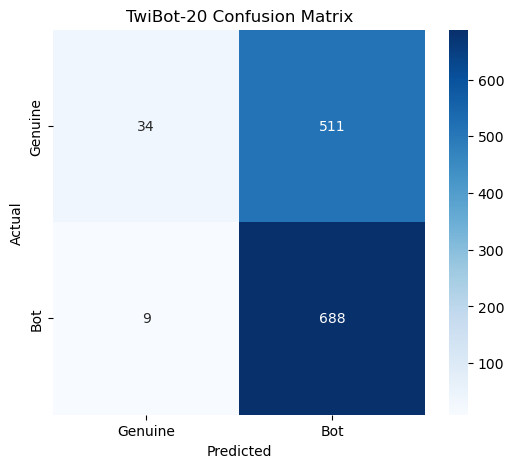

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Bot"],
    yticklabels=["Genuine", "Bot"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TwiBot-20 Confusion Matrix")

plt.show()

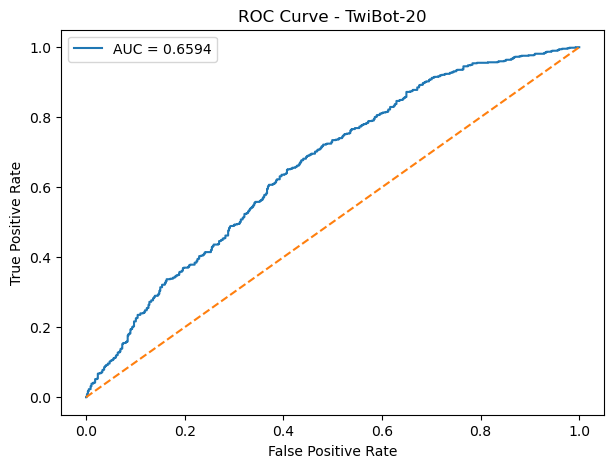

In [46]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    probabilities
)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - TwiBot-20"
)

plt.legend()

plt.show()

In [47]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=[
            "Genuine",
            "Bot"
        ]
    )
)

              precision    recall  f1-score   support

     Genuine       0.79      0.06      0.12       545
         Bot       0.57      0.99      0.73       697

    accuracy                           0.58      1242
   macro avg       0.68      0.52      0.42      1242
weighted avg       0.67      0.58      0.46      1242



In [5]:
import pandas as pd

# Path to TwiBot-20
file_path = "TwiBot-20/train.json"

# Load the dataset
df = pd.read_json(file_path)

# Display first 10 records
print(df.head(3))
            

                    ID                                            profile  \
0             17461978  {'id': '17461978 ', 'id_str': '17461978 ', 'na...   
1  1297437077403885568  {'id': '1297437077403885568 ', 'id_str': '1297...   
2             17685258  {'id': '17685258 ', 'id_str': '17685258 ', 'na...   

                                               tweet  \
0  [RT @CarnivalCruise: 🎉 Are you ready to see wh...   
1                                               None   
2  [RT @realDonaldTrump: THANK YOU #RNC2020! http...   

                                            neighbor  \
0                                               None   
1  {'following': ['170861207', '23970102', '47293...   
2  {'following': ['46464108', '21536398', '186434...   

                                domain  label  
0  [Politics, Business, Entertainment]      0  
1                           [Politics]      1  
2    [Politics, Entertainment, Sports]      0  
